<a href="https://colab.research.google.com/github/deva1320/MLA0202---ML/blob/main/Exp_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

INPUT DATA:
X1  X2  Target
0   0     0
0   1     1
1   0     1
1   1     0

TRAINED NETWORK RESULTS
----------------------------------------
Input	Actual	Predicted Probability	Class
[0 0] 	 0 	 0.0001 		 0
[0 1] 	 1 	 0.9998 		 1
[1 0] 	 1 	 0.9997 		 1
[1 1] 	 0 	 0.0003 		 0

Final Training Loss: 0.000218
Training Accuracy: 100.0 %


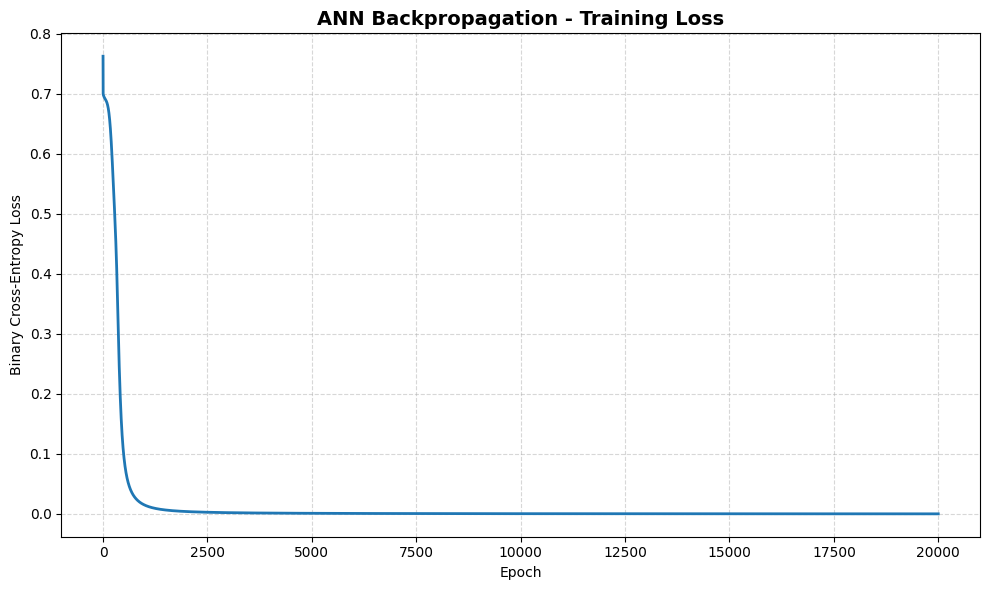


RESULT:
Artificial Neural Network trained using backpropagation.
XOR input patterns were classified.


In [1]:

# ============================================================
# MLA02 - FUNDAMENTALS OF MACHINE LEARNING
# EXPERIMENT 4 - ANN USING BACKPROPAGATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ------------------------------------------------------------
# 1. Input Dataset (XOR)
# ------------------------------------------------------------

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

print("INPUT DATA:")
print("X1  X2  Target")

for inputs, target in zip(X, y):
    print(int(inputs[0]), " ", int(inputs[1]),
          "   ", int(target[0]))

# ------------------------------------------------------------
# 2. Initialize Neural Network
# Architecture: 2 input neurons, 4 hidden neurons,
#               1 output neuron
# ------------------------------------------------------------

input_neurons = 2
hidden_neurons = 4
output_neurons = 1

W1 = np.random.randn(input_neurons, hidden_neurons)
b1 = np.zeros((1, hidden_neurons))

W2 = np.random.randn(hidden_neurons, output_neurons)
b2 = np.zeros((1, output_neurons))

learning_rate = 1.0
epochs = 20000

loss_history = []

# ------------------------------------------------------------
# 3. Sigmoid Activation Function
# ------------------------------------------------------------

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# ------------------------------------------------------------
# 4. Training using Backpropagation
# ------------------------------------------------------------

for epoch in range(epochs):

    # Forward propagation
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)

    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Binary cross-entropy loss
    eps = 1e-12
    loss = -np.mean(
        y * np.log(a2 + eps)
        + (1 - y) * np.log(1 - a2 + eps)
    )

    loss_history.append(loss)

    # Backward propagation
    dz2 = (a2 - y) / len(X)
    dW2 = np.dot(a1.T, dz2)
    db2 = np.sum(dz2, axis=0, keepdims=True)

    dz1 = np.dot(dz2, W2.T) * a1 * (1 - a1)
    dW1 = np.dot(X.T, dz1)
    db1 = np.sum(dz1, axis=0, keepdims=True)

    # Update weights and biases
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

# ------------------------------------------------------------
# 5. Test the Trained Network
# ------------------------------------------------------------

hidden_output = sigmoid(np.dot(X, W1) + b1)
predictions = sigmoid(np.dot(hidden_output, W2) + b2)

predicted_classes = (predictions >= 0.5).astype(int)

print("\nTRAINED NETWORK RESULTS")
print("-" * 40)
print("Input\tActual\tPredicted Probability\tClass")

for i in range(len(X)):
    print(
        X[i].astype(int),
        "\t",
        int(y[i, 0]),
        "\t",
        round(predictions[i, 0], 4),
        "\t\t",
        predicted_classes[i, 0]
    )

accuracy = np.mean(predicted_classes == y) * 100

print("\nFinal Training Loss:", round(loss_history[-1], 6))
print("Training Accuracy:", round(accuracy, 2), "%")

# ------------------------------------------------------------
# 6. Plot Training Loss
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(loss_history, linewidth=2)

plt.title(
    "ANN Backpropagation - Training Loss",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Result
# ------------------------------------------------------------

print("\nRESULT:")
print("Artificial Neural Network trained using backpropagation.")
print("XOR input patterns were classified.")
